# Aim : To perform and analysis of ensemble technique 

In [17]:
# Name: Sanika Vijay Kale
# Roll No.: 23
# Branch: B.E. CSE (Data Science)
# Year: Final Year
# Semester: VII
# Academic Year: 2026-27

In [16]:
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    BaggingClassifier,
    AdaBoostClassifier
)
from sklearn.metrics import accuracy_score
import inspect

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset loaded successfully!")
print("Number of rows:", X.shape[0])
print("Number of features:", X.shape[1])
print("Target classes:", data.target_names)

Dataset loaded successfully!
Number of rows: 569
Number of features: 30
Target classes: ['malignant' 'benign']


In [3]:
df = pd.DataFrame(X, columns=data.feature_names)
df["Target"] = y

display(df.head())

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 455
Testing samples: 114


In [5]:
# 1. Bagging model
bagging_params = {
    "n_estimators": 50,
    "random_state": 42
}

if "estimator" in inspect.signature(BaggingClassifier).parameters:
    bagging_params["estimator"] = DecisionTreeClassifier(random_state=42)
else:
    bagging_params["base_estimator"] = DecisionTreeClassifier(random_state=42)

bagging_model = BaggingClassifier(**bagging_params)

# 2. Random Forest model
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# 3. Boosting model
boosting_model = AdaBoostClassifier(
    n_estimators=50,
    random_state=42
)

print("All three ensemble models created successfully!")

All three ensemble models created successfully!


In [6]:
bagging_model.fit(X_train, y_train)
print("Bagging model trained successfully!")

random_forest_model.fit(X_train, y_train)
print("Random Forest model trained successfully!")

boosting_model.fit(X_train, y_train)
print("Boosting model trained successfully!")

Bagging model trained successfully!
Random Forest model trained successfully!
Boosting model trained successfully!


In [7]:
bagging_pred = bagging_model.predict(X_test)

random_forest_pred = random_forest_model.predict(X_test)

boosting_pred = boosting_model.predict(X_test)

print("Predictions generated successfully!")
print("First 10 actual values:     ", y_test[:10])
print("First 10 Bagging predictions:", bagging_pred[:10])

Predictions generated successfully!
First 10 actual values:      [0 1 0 1 0 1 1 0 0 0]
First 10 Bagging predictions: [0 1 0 0 0 1 1 0 0 0]


In [12]:
bagging_accuracy = accuracy_score(y_test, bagging_pred)

random_forest_accuracy = accuracy_score(y_test, random_forest_pred)

boosting_accuracy = accuracy_score(y_test, boosting_pred)

print(f"Bagging Accuracy:       {bagging_accuracy * 100:.2f}%")
print(f"Random Forest Accuracy: {random_forest_accuracy * 100:.2f}%")
print(f"Boosting Accuracy:      {boosting_accuracy * 100:.2f}%")

Bagging Accuracy:       93.86%
Random Forest Accuracy: 95.61%
Boosting Accuracy:      95.61%


In [13]:
results = pd.DataFrame({
    "Ensemble Technique": [
        "Bagging",
        "Random Forest",
        "Boosting"
    ],
    "Accuracy (%)": [
        bagging_accuracy * 100,
        random_forest_accuracy * 100,
        boosting_accuracy * 100
    ]
})

results = results.sort_values(
    by="Accuracy (%)",
    ascending=False
).reset_index(drop=True)

display(results.round(2))

,Ensemble Technique,Accuracy (%)
0,Random Forest,95.61
1,Boosting,95.61
2,Bagging,93.86


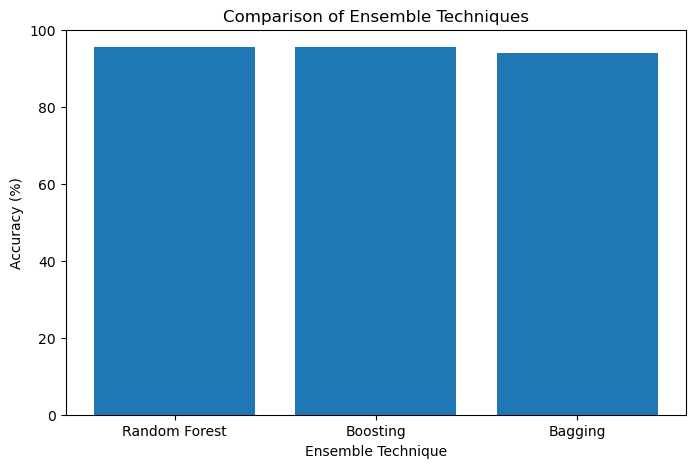

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    results["Ensemble Technique"],
    results["Accuracy (%)"]
)

plt.title("Comparison of Ensemble Techniques")
plt.xlabel("Ensemble Technique")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.show()

In [11]:
best_model = results.iloc[0]

print("Best Performing Technique:", best_model["Ensemble Technique"])
print("Accuracy:", round(best_model["Accuracy (%)"], 2), "%")

Best Performing Technique: Random Forest
Accuracy: 95.61 %
